## Planning:
- Load data
- Explore Data
- Log data
- Check data correlation

## Loading Data

In [64]:
import pandas as pd
import numpy as np

In [65]:
from pathlib import Path

In [66]:
current_dir = Path.cwd()
competition_root = current_dir.parents[1]

In [67]:
competition_path = competition_root/"One Dollar"

In [68]:
train = pd.read_csv(competition_path/"data/train.csv")
test = pd.read_csv(competition_path/"data/test.csv")
submit = pd.read_csv(competition_path/"data/sample_submission.csv")

In [69]:
train.shape

(15000, 13)

In [70]:
train.head()

,id,Hardness,allelectrons_Total,density_Total,allelectrons_Average,val_e_Average,atomicweight_Average,ionenergy_Average,el_neg_chi_Average,R_vdw_element_Average,R_cov_element_Average,zaratio_Average,density_Average
0,0,6.0,250.0,27.105990,12.0,4.8,25.408218,11.330440,2.757000,1.7000,0.945000,0.488270,1.00660
1,1,5.0,42.0,1.742832,8.0,3.5,17.790357,12.184250,2.727500,1.5450,0.710000,0.618493,0.65972
2,2,3.8,96.0,8.841328,9.5,3.0,19.397353,13.161829,2.788333,1.5450,0.723333,0.659870,1.23121
3,3,2.5,150.0,23.576975,50.0,4.0,167.400000,10.776008,2.240000,2.0150,1.180000,0.457615,7.77500
4,4,6.8,80.0,7.734660,10.0,5.0,20.255278,11.026725,2.790000,1.6725,0.852500,0.495275,1.02228


In [71]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     15000 non-null  int64  
 1   Hardness               15000 non-null  float64
 2   allelectrons_Total     15000 non-null  float64
 3   density_Total          15000 non-null  float64
 4   allelectrons_Average   15000 non-null  float64
 5   val_e_Average          15000 non-null  float64
 6   atomicweight_Average   15000 non-null  float64
 7   ionenergy_Average      15000 non-null  float64
 8   el_neg_chi_Average     15000 non-null  float64
 9   R_vdw_element_Average  15000 non-null  float64
 10  R_cov_element_Average  15000 non-null  float64
 11  zaratio_Average        15000 non-null  float64
 12  density_Average        15000 non-null  float64
dtypes: float64(12), int64(1)
memory usage: 1.5 MB


In [72]:
test.shape

(10000, 12)

## Data Visualisation

### Missing Value

In [73]:
# missing train
train_missing = pd.DataFrame(train.isna().sum()).reset_index()

In [74]:
train_missing

,index,0
0,id,0
1,Hardness,0
2,allelectrons_Total,0
3,density_Total,0
4,allelectrons_Average,0
5,val_e_Average,0
6,atomicweight_Average,0
7,ionenergy_Average,0
8,el_neg_chi_Average,0
9,R_vdw_element_Average,0


In [75]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     15000 non-null  int64  
 1   Hardness               15000 non-null  float64
 2   allelectrons_Total     15000 non-null  float64
 3   density_Total          15000 non-null  float64
 4   allelectrons_Average   15000 non-null  float64
 5   val_e_Average          15000 non-null  float64
 6   atomicweight_Average   15000 non-null  float64
 7   ionenergy_Average      15000 non-null  float64
 8   el_neg_chi_Average     15000 non-null  float64
 9   R_vdw_element_Average  15000 non-null  float64
 10  R_cov_element_Average  15000 non-null  float64
 11  zaratio_Average        15000 non-null  float64
 12  density_Average        15000 non-null  float64
dtypes: float64(12), int64(1)
memory usage: 1.5 MB


In [76]:
# missing test
test_missing = pd.DataFrame(test.isna().sum()).reset_index()

In [77]:
test_missing

,index,0
0,id,0
1,allelectrons_Total,0
2,density_Total,0
3,allelectrons_Average,0
4,val_e_Average,0
5,atomicweight_Average,0
6,ionenergy_Average,0
7,el_neg_chi_Average,0
8,R_vdw_element_Average,0
9,R_cov_element_Average,0


## Key Stats

In [78]:
train.describe()

,id,Hardness,allelectrons_Total,density_Total,allelectrons_Average,val_e_Average,atomicweight_Average,ionenergy_Average,el_neg_chi_Average,R_vdw_element_Average,R_cov_element_Average,zaratio_Average,density_Average
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,1.500000e+04,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7499.500000,4.421263,125.220709,13.168250,16.507343,4.447046,3.573151e+02,10.788980,2.547634,1.720777,0.941916,0.489042,1.896446
std,4330.271354,1.721446,302.337242,17.551363,10.805374,0.841425,3.931382e+04,1.835890,0.441645,0.272693,0.208014,0.081936,1.880060
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3749.750000,2.500000,63.750000,5.686908,10.000000,4.000000,2.018540e+01,10.398750,2.330000,1.672500,0.880000,0.476095,0.748760
50%,7499.500000,4.900000,99.000000,9.133000,12.000000,4.666667,2.478962e+01,11.177555,2.700400,1.738000,0.926000,0.489486,1.050950
75%,11249.250000,6.000000,126.000000,14.959782,21.750000,4.800000,4.798569e+01,11.684513,2.790000,1.870000,1.028000,0.496593,2.292800
max,14999.000000,10.000000,15300.000000,643.093804,116.000000,6.000000,4.814975e+06,15.245810,3.443000,2.280000,1.900000,0.825990,10.970000


In [79]:
test.describe()

,id,allelectrons_Total,density_Total,allelectrons_Average,val_e_Average,atomicweight_Average,ionenergy_Average,el_neg_chi_Average,R_vdw_element_Average,R_cov_element_Average,zaratio_Average,density_Average
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,19999.50000,120.713467,12.965366,16.564324,4.425205,36.449179,10.772577,2.544402,1.719397,0.940854,0.488459,1.893341
std,2886.89568,159.597100,13.809102,10.899072,0.854228,26.907702,1.861350,0.449000,0.278275,0.210572,0.081193,1.872533
min,15000.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17499.75000,64.000000,5.625328,10.000000,4.000000,20.213349,10.398750,2.330000,1.672500,0.880000,0.476095,0.751930
50%,19999.50000,98.000000,9.133000,12.000000,4.666667,24.789618,11.177555,2.698000,1.738000,0.923000,0.489507,1.054280
75%,22499.25000,126.000000,14.939458,21.250000,4.800000,47.697010,11.667433,2.790000,1.870000,1.028000,0.496392,2.281260
max,24999.00000,3328.000000,203.382000,100.000000,6.000000,167.400000,15.245810,3.891818,2.280000,1.614000,0.825990,10.970000


### Data Distribution

In [80]:
import seaborn as sns
import matplotlib.pyplot as plt

In [81]:
data_viz = train.drop(columns = ["id"])

In [82]:
num_cols = train.drop(columns=["id"]).select_dtypes(include="number").columns.to_list()

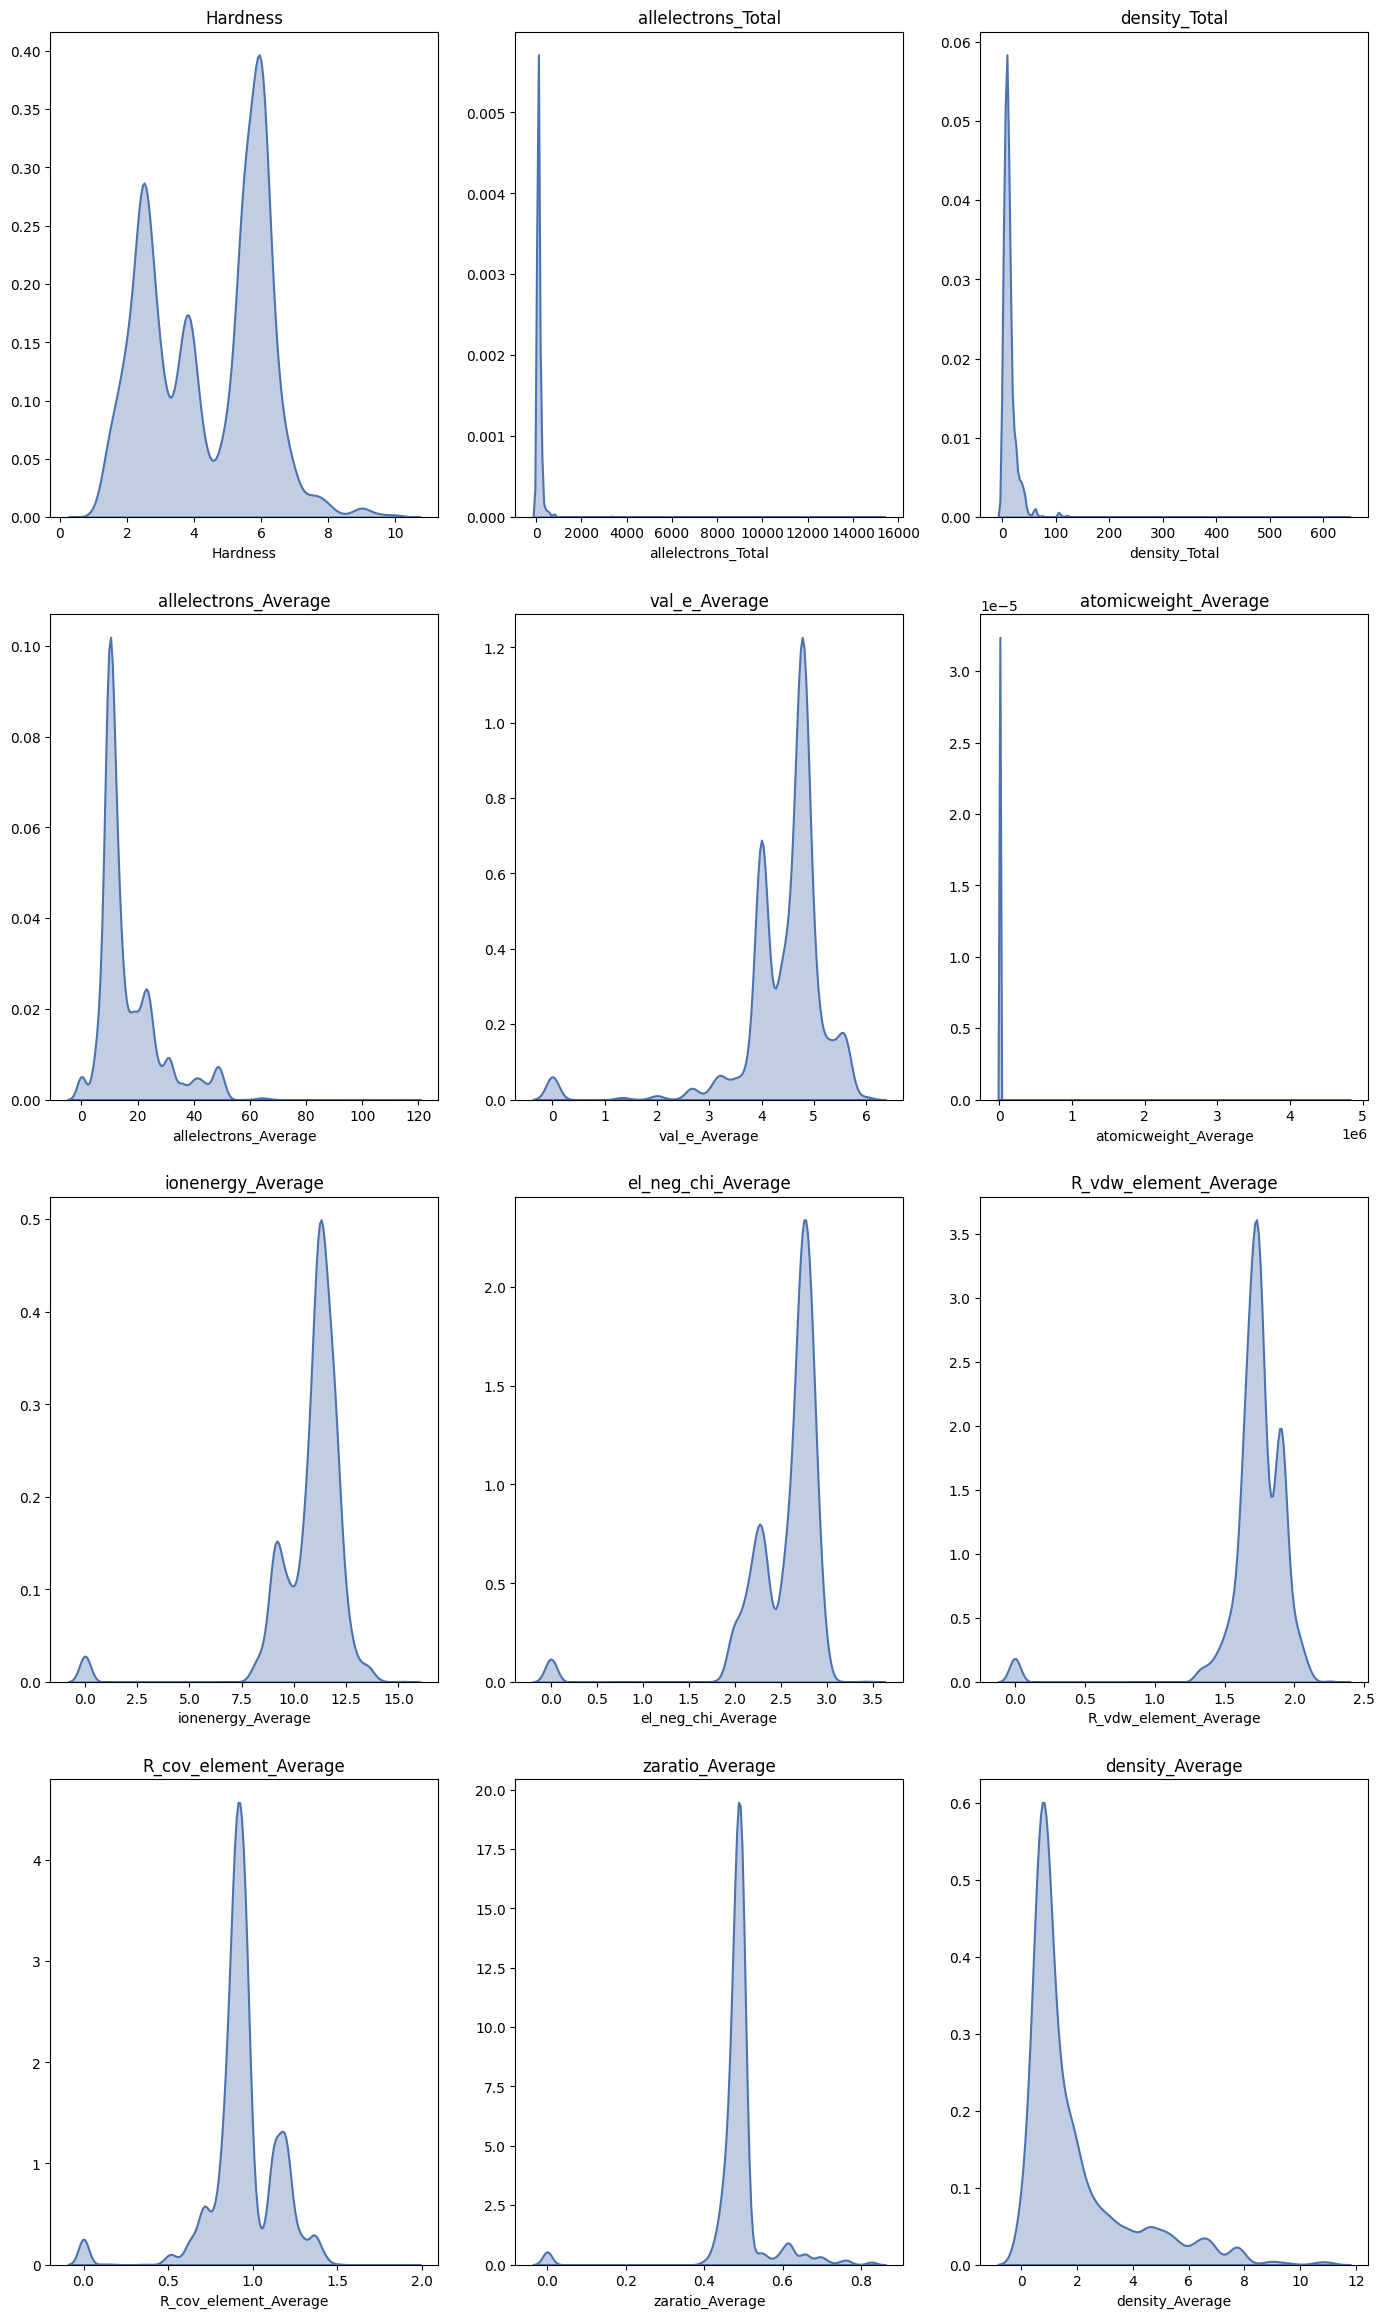

In [83]:
fig, axes = plt.subplots(4, 3, figsize=(17, 29))

for ax, col in zip(axes.flatten(), num_cols):
    sns.kdeplot(data_viz.loc[:, col].dropna(),
        ax=ax, 
        fill=True, 
        alpha=0.35, 
        color="#4C72B0", 
        linewidth=1.5)
    ax.set_title(col)
    ax.set_ylabel("")

## Comparing Train and Test Distribution

In [86]:
# tagging for train
train_c = train.drop(columns = ["Hardness"])
train_c["tag"] = "train"

# tagging for test
test_c = test.copy()
test_c["tag"] = "test"

In [87]:
# combine test and tag
combined = pd.concat([train_c,test_c],ignore_index=True)

In [88]:
combined.shape

(25000, 13)

**Visualizing Difference**

In [90]:
PALETTE = {"train": "#4C72B0", "test": "#DD8452"}  
# 4C72B0 = Blue
# DD8452 = Orange

In [91]:
num_cols_c = combined.drop(columns=["id"]).select_dtypes(include="number").columns.to_list()

In [92]:
data_viz_c = combined.drop(columns = ["id"])

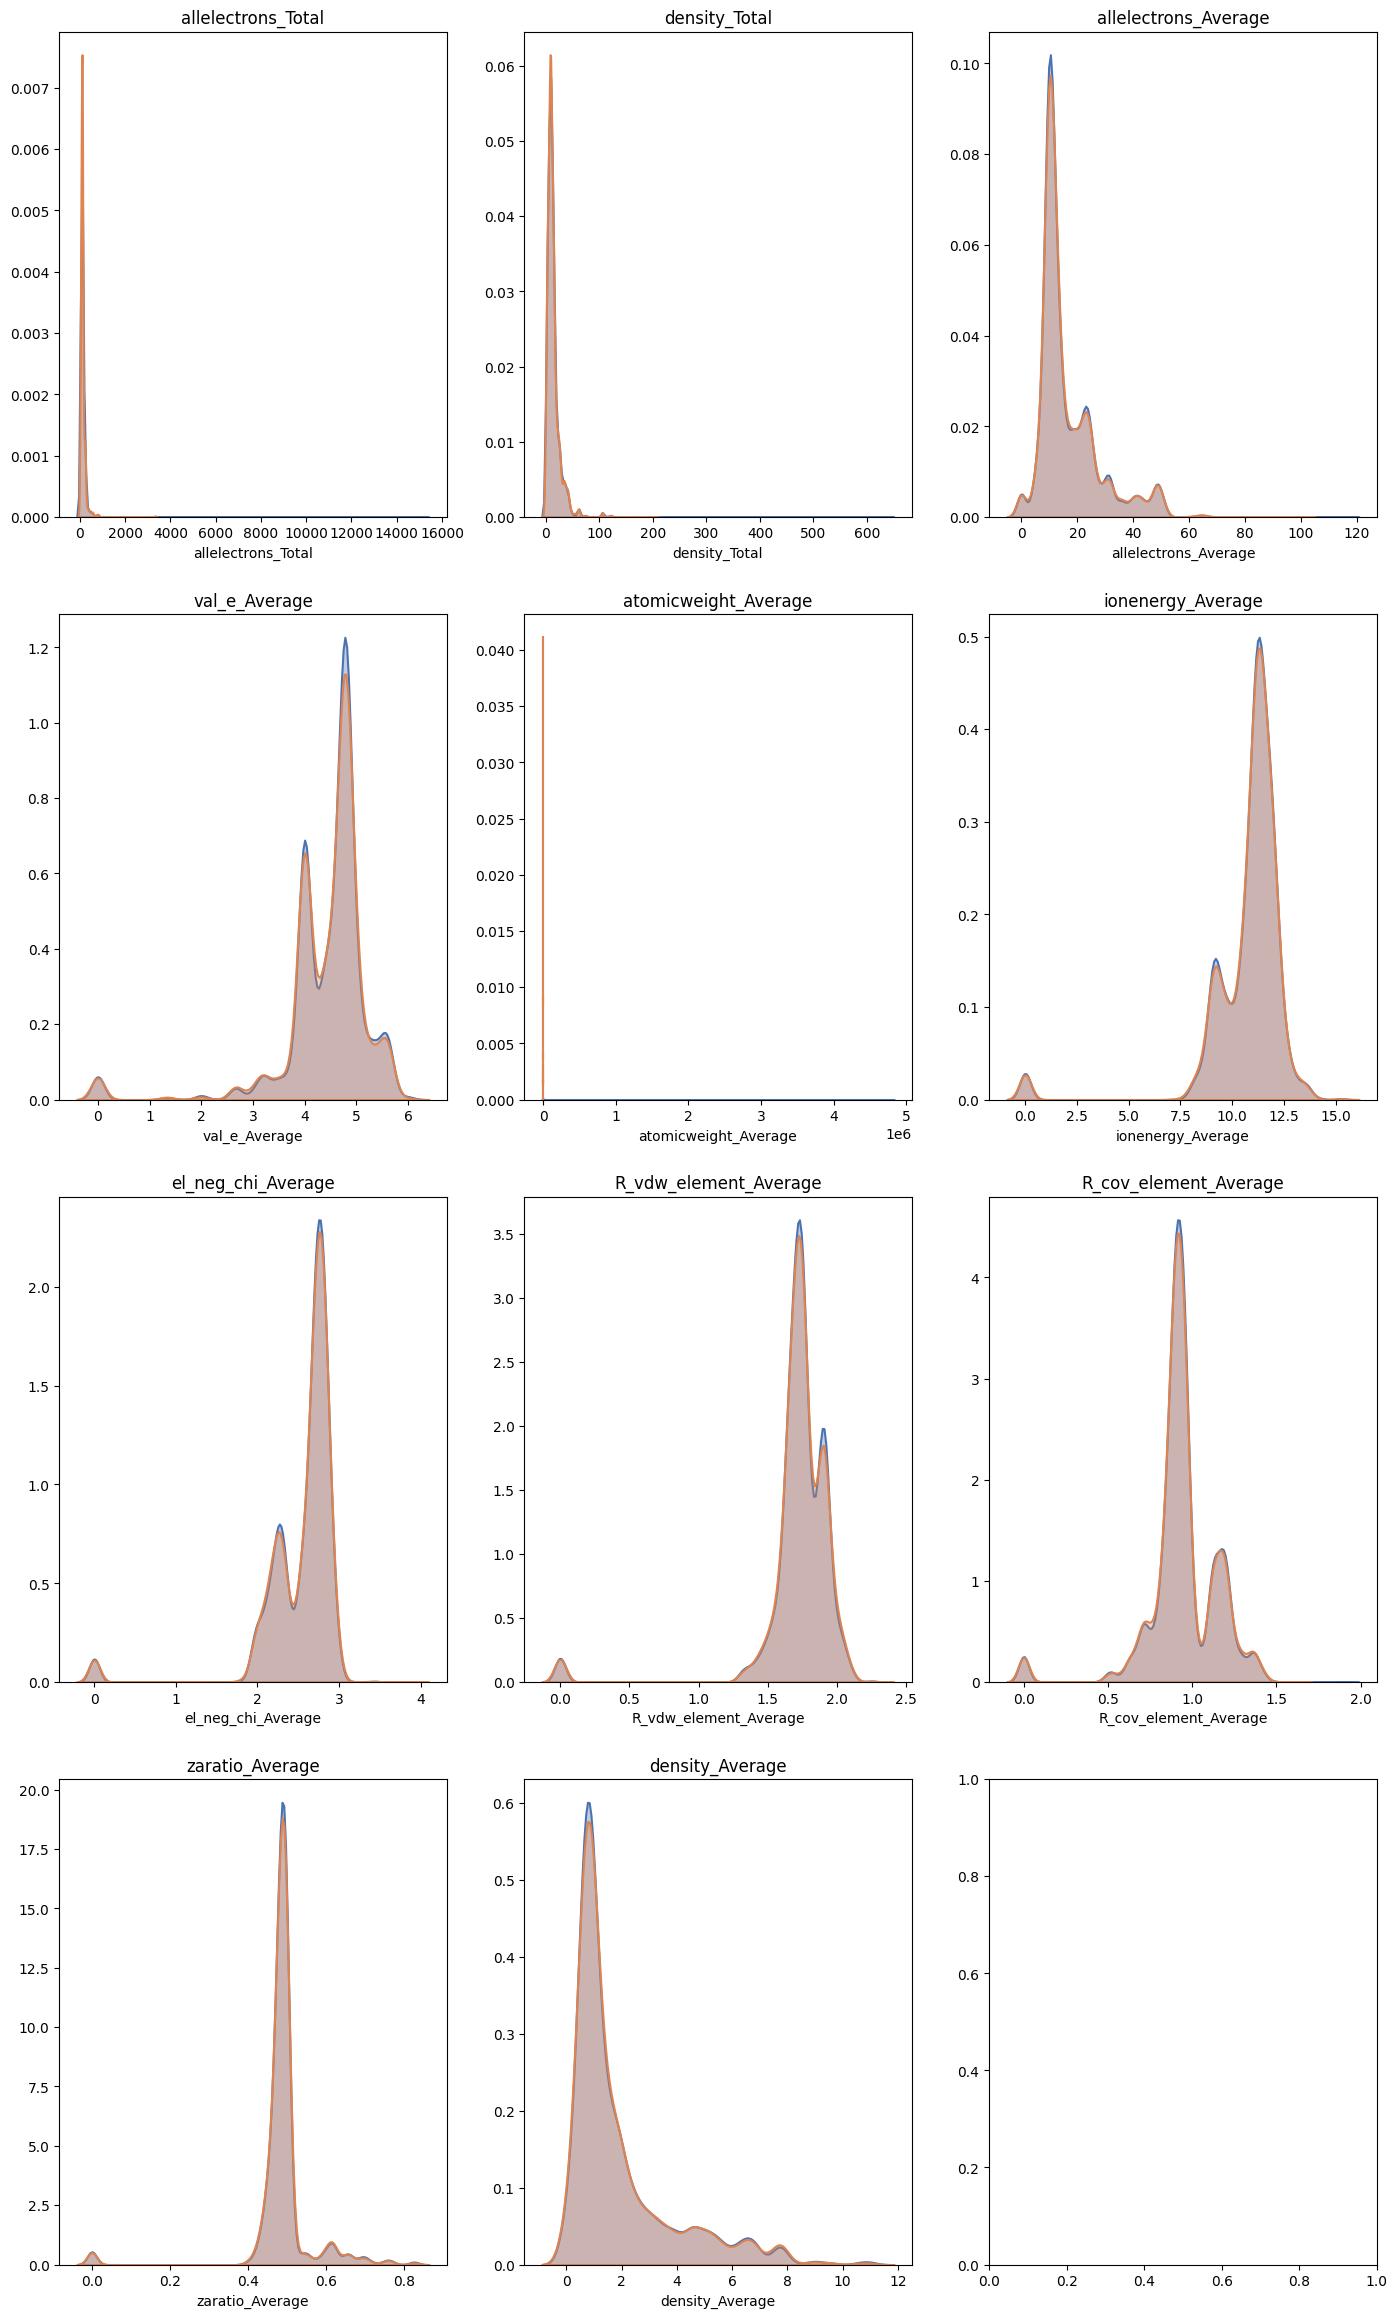

In [99]:
fig, axes = plt.subplots(4, 3, figsize=(17, 29))

for ax, col in zip(axes.flatten(), num_cols_c):
    for label, color in PALETTE.items():
        sns.kdeplot(data_viz_c.loc[data_viz_c["tag"] == label, col].dropna(),
                    ax=ax, 
                    fill=True, 
                    alpha=0.35, 
                    color=color, 
                    linewidth=1.5,
                    label=str(label))
    ax.set_title(col)
    ax.set_ylabel("")

**Side by Side Comparison**

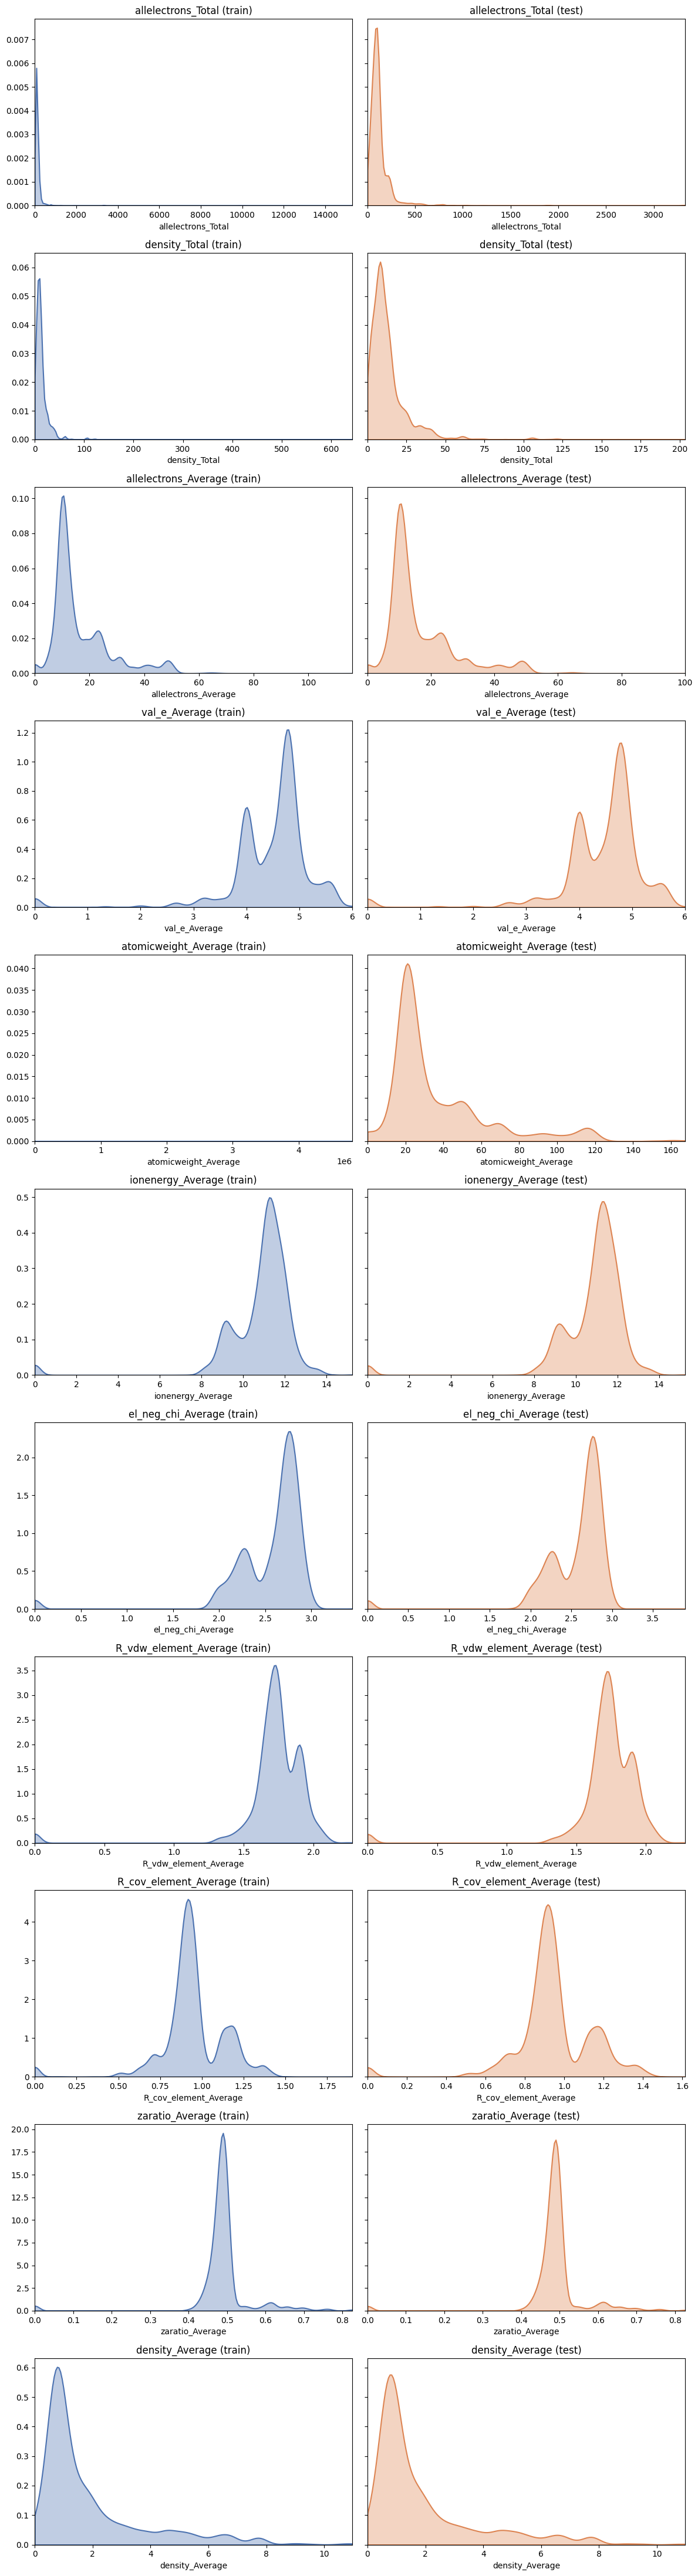

In [101]:
fig, axes = plt.subplots(len(num_cols_c), 2, figsize=(12, 4 * len(num_cols_c)), sharey="row")

for i, col in enumerate(num_cols_c):
    for j, (label, color) in enumerate(PALETTE.items()):
        ax = axes[i, j]
        subset = data_viz_c.loc[data_viz_c["tag"] == label, col].dropna()
        
        sns.kdeplot(
            subset,
            ax=ax,
            fill=True,
            alpha=0.35,
            color=color,
            linewidth=1.5,
            clip=(subset.min(), subset.max())
        )
        ax.set_xlim(subset.min(), subset.max())
        ax.set_title(f"{col} ({label})")
        ax.set_ylabel("")

plt.tight_layout()

In [106]:
train["atomicweight_Average"].describe().apply(lambda x: f"{x:.6f}")

count      15000.000000
mean         357.315110
std        39313.818680
min            0.000000
25%           20.185396
50%           24.789618
75%           47.985687
max      4814975.000000
Name: atomicweight_Average, dtype: object

In [107]:
test["atomicweight_Average"].describe()

count    10000.000000
mean        36.449179
std         26.907702
min          0.000000
25%         20.213349
50%         24.789618
75%         47.697010
max        167.400000
Name: atomicweight_Average, dtype: float64

## Checking Outlier in Train

In [108]:
outliers = train[train["allelectrons_Total"] > test["allelectrons_Total"].max()]

In [109]:
outliers.shape

(6, 13)

## Normalizing Outlier using Natural Logarithm

In [39]:
train["ln_allelectrons_Total"] = np.log1p(train["allelectrons_Total"])

<Axes: >

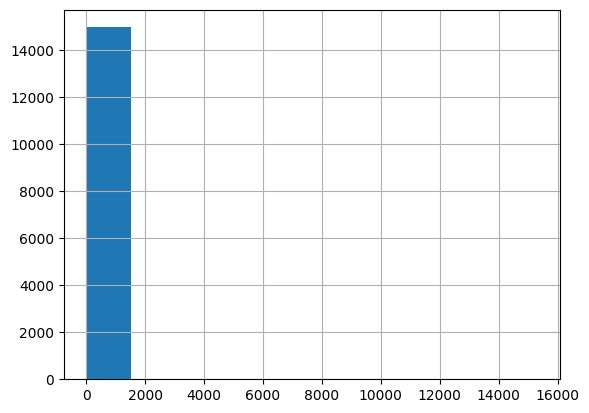

In [41]:
train["allelectrons_Total"].hist()

<Axes: >

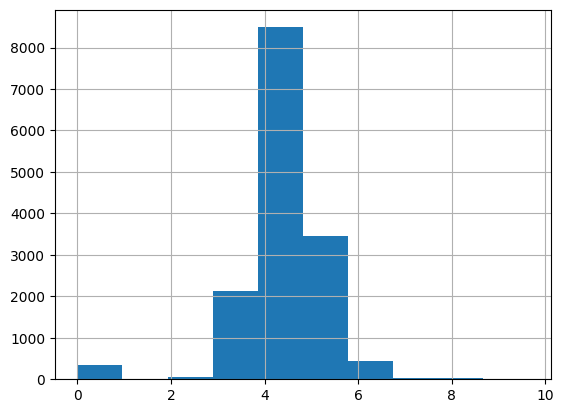

In [42]:
train["ln_allelectrons_Total"].hist()

In [44]:
ln_var = ['allelectrons_Total','density_Total','atomicweight_Average']

In [45]:
for col in ln_var:
    train[f'ln_{col}'] = np.log1p(train[col])
    test[f'ln_{col}'] = np.log1p(test[col])

In [48]:
train_cl = train.drop(columns= ln_var). copy()
test_cl = test.drop(columns=ln_var).copy()

In [49]:
num_cols_cl = train_cl.drop(columns=["id"]).select_dtypes(include="number").columns.to_list()

In [50]:
data_viz_cl = train_cl.drop(columns = ["id"])

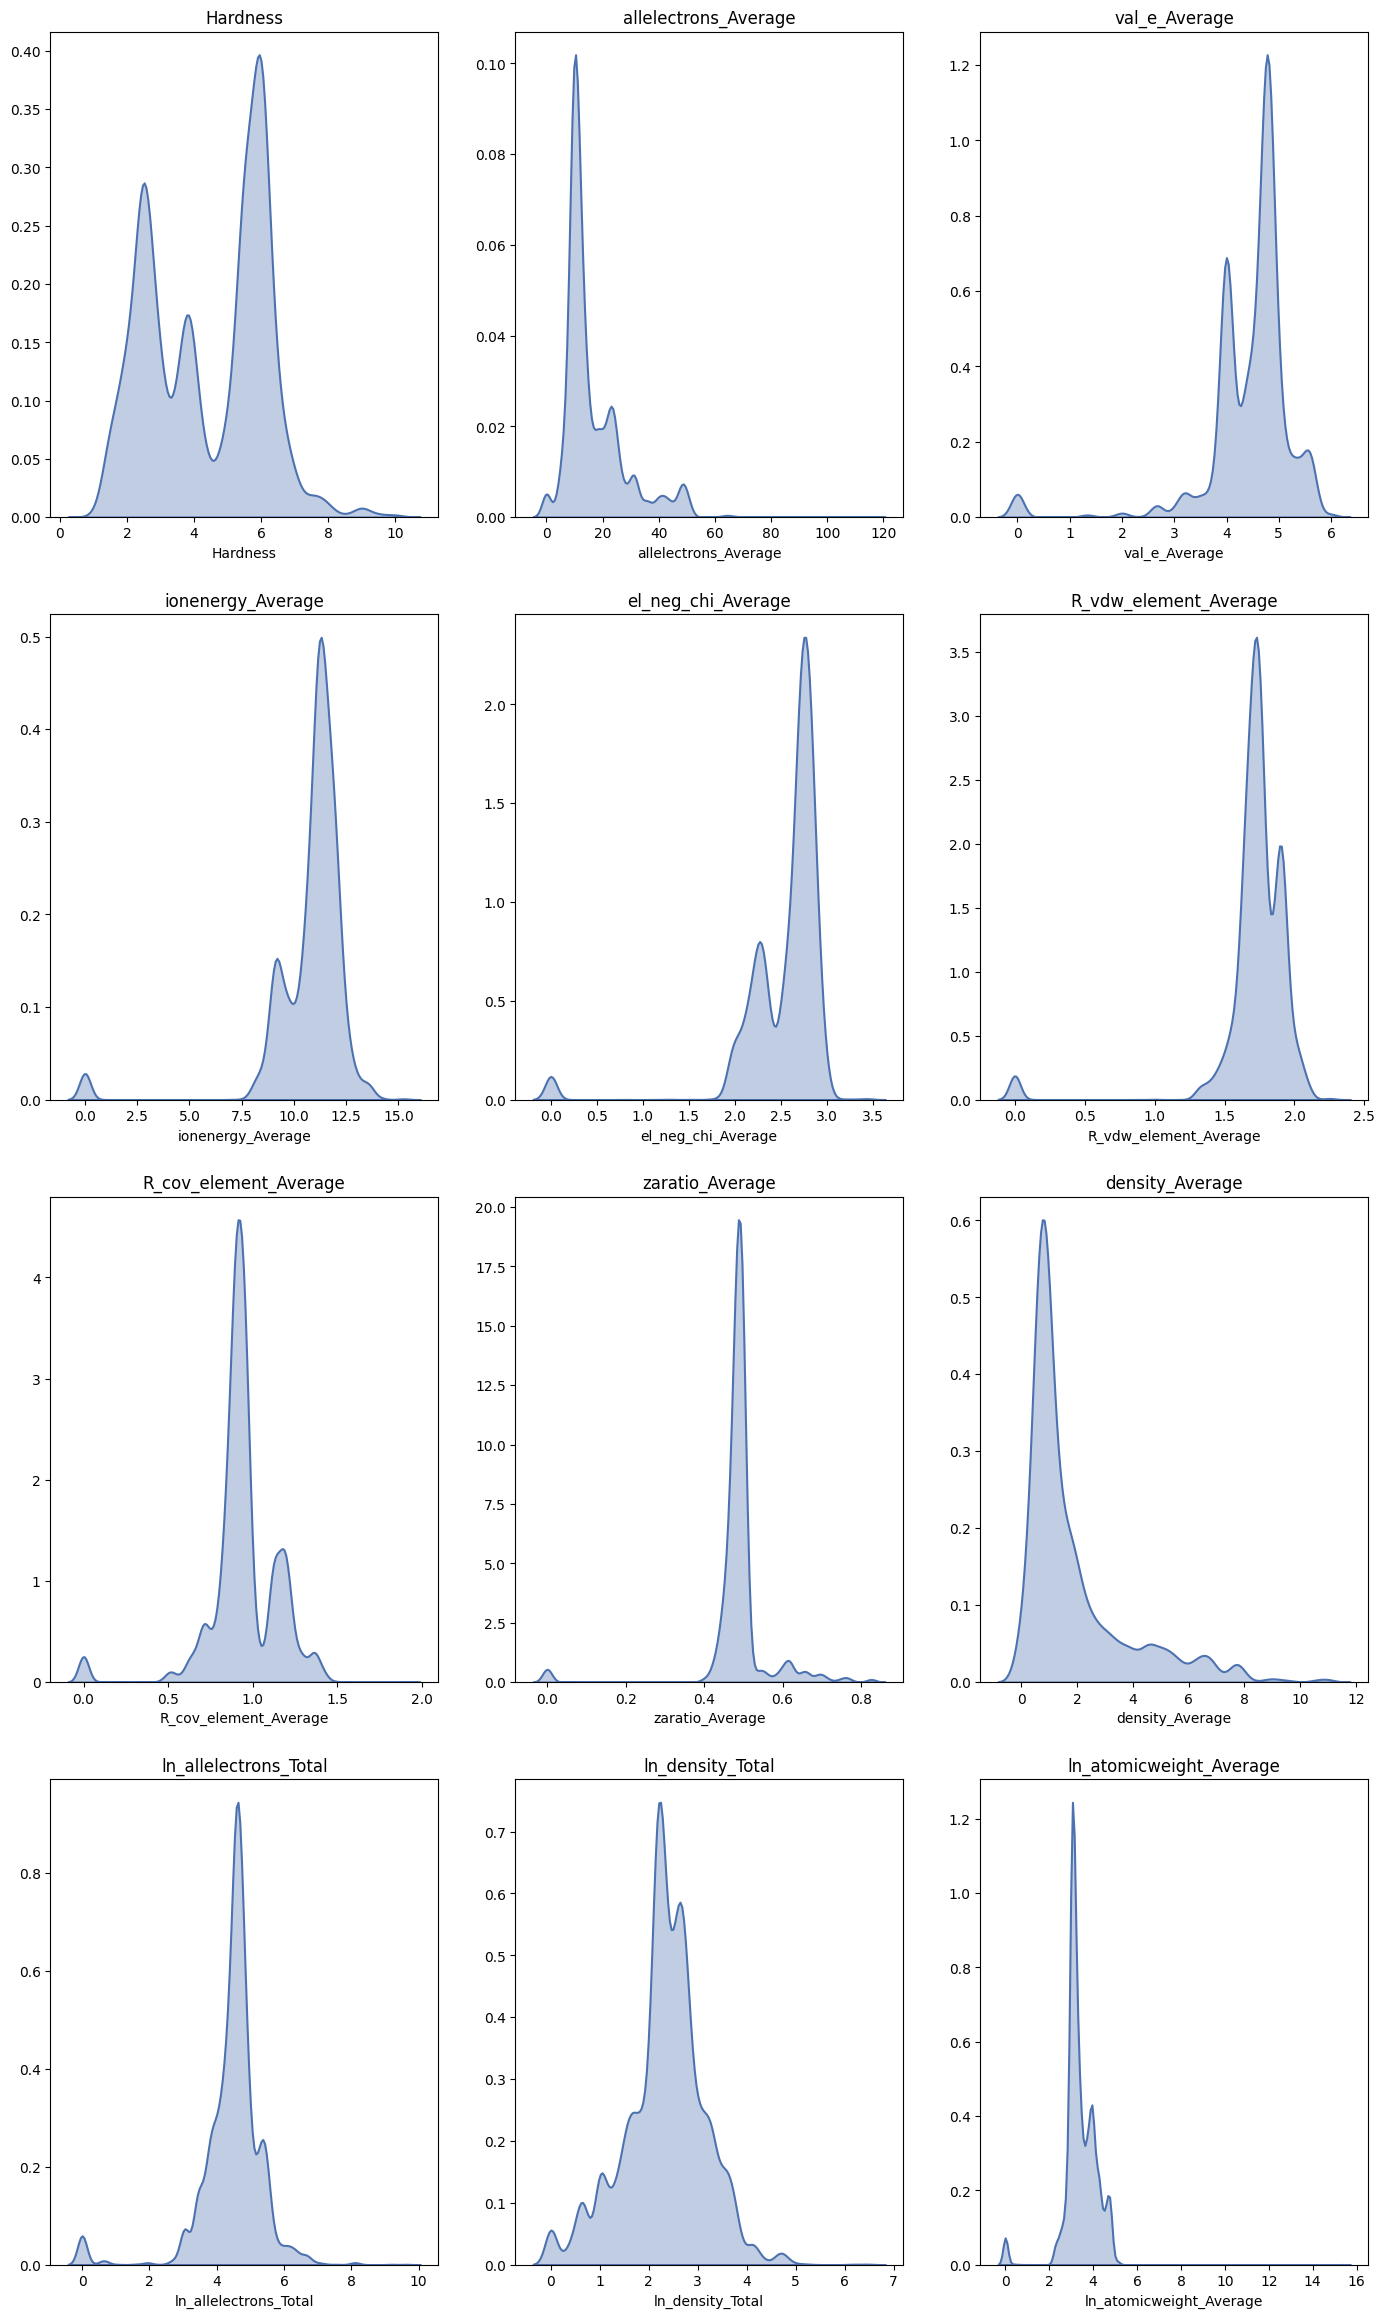

In [51]:
fig, axes = plt.subplots(4, 3, figsize=(17, 29))

for ax, col in zip(axes.flatten(), num_cols_cl):
    sns.kdeplot(data_viz_cl.loc[:, col].dropna(),
        ax=ax, 
        fill=True, 
        alpha=0.35, 
        color="#4C72B0", 
        linewidth=1.5)
    ax.set_title(col)
    ax.set_ylabel("")

## Data Correlation

In [56]:
matrix_corr = train_cl[num_cols_cl].corr()

In [58]:
matrix_corr

,Hardness,allelectrons_Average,val_e_Average,ionenergy_Average,el_neg_chi_Average,R_vdw_element_Average,R_cov_element_Average,zaratio_Average,density_Average,ln_allelectrons_Total,ln_density_Total,ln_atomicweight_Average
Hardness,1.000000,-0.326394,0.210888,0.217585,0.314430,0.039096,-0.085634,0.083019,-0.268190,0.069680,-0.024600,-0.135405
allelectrons_Average,-0.326394,1.000000,0.107954,-0.174706,-0.130219,0.493915,0.658289,-0.145621,0.775818,0.326528,0.508545,0.837503
val_e_Average,0.210888,0.107954,1.000000,0.626037,0.710574,0.605214,0.423209,0.382634,0.017101,0.565498,0.350324,0.465291
ionenergy_Average,0.217585,-0.174706,0.626037,1.000000,0.851107,0.492248,0.165029,0.760138,-0.195995,0.497297,0.151145,0.236650
el_neg_chi_Average,0.314430,-0.130219,0.710574,0.851107,1.000000,0.508248,0.210487,0.621345,-0.153145,0.542366,0.225515,0.292012
R_vdw_element_Average,0.039096,0.493915,0.605214,0.492248,0.508248,1.000000,0.853403,0.402048,0.354709,0.592256,0.456472,0.796287
R_cov_element_Average,-0.085634,0.658289,0.423209,0.165029,0.210487,0.853403,1.000000,0.134477,0.493614,0.463197,0.447387,0.814391
zaratio_Average,0.083019,-0.145621,0.382634,0.760138,0.621345,0.402048,0.134477,1.000000,-0.168929,0.387523,0.075748,0.166509
density_Average,-0.268190,0.775818,0.017101,-0.195995,-0.153145,0.354709,0.493614,-0.168929,1.000000,0.264629,0.528535,0.656226
ln_allelectrons_Total,0.069680,0.326528,0.565498,0.497297,0.542366,0.592256,0.463197,0.387523,0.264629,1.000000,0.731548,0.587508


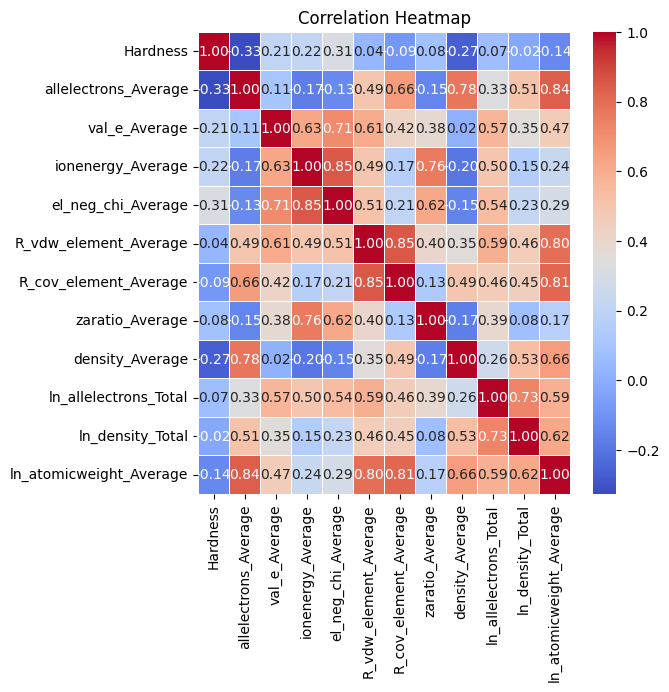

In [57]:
plt.figure(figsize=(6,6))
sns.heatmap(matrix_corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

## What should be the first treatment?

- Drop atomicweight_Average
- take care outlier in allelectron total - drop outlier